# A unit root test with a broken trend: the T-Bill rate

In the solution to Exercise 4 we tested the 3-month T-Bill rate for a unit root with an intercept only, and noted that one could argue for a *breaking trend* instead (upwards until the early 1980s, downwards thereafter), "but this kind of test is not available in `statsmodels`".

The problem is not the test regression, which is easy to run. The problem is the **critical value**: under the null of a unit root, the distribution of the Dickey-Fuller $t$-statistic depends on which deterministic terms are in the regression, and with a break it depends on *where* the break is. Until recently one had to simulate it, or look it up in tables for a few break dates (Perron, 1989).

This is no longer so. The exact limiting distribution of the Dickey-Fuller $t$-ratio with breaks in level and slope at any known date is derived in Bao, Broda and Kan (2026), ["The Exact Limiting Distribution of the Dickey-Fuller t-Ratio with General Deterministic Terms"](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=7745921), and implemented in the Python package `dflimit`. A critical value or a $p$-value takes a fraction of a second, so we can compute them on the fly while we move the break around.

**Requirements:** `dflimit` version 0.5 or later (`pip install dflimit`) and `ipywidgets` for the slider.

In [1]:
import os
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.tsa.api as tsa
import ipywidgets as widgets
from IPython.display import display
from dflimit import perron, trend, dist_cdf, dist_pdf, dist_quantile

In [2]:
DATA_PATH = os.path.join("..", "..", "..", "data")
df = pd.read_csv(os.path.join(DATA_PATH, "tbill.csv"), index_col="DATE")
df.index = pd.DatetimeIndex(df.index, dayfirst=True).to_period('M')
y = df["TBILL3M"].to_numpy()
dates = df.index
n = len(y)
print(n, "monthly observations,", dates[0], "to", dates[-1])

1066 monthly observations, 1934-01 to 2022-10


## The test regression

The ADF regression with a broken trend is the usual one,
$$ \Delta y_{t}= d_t'\beta+\psi y_{t-1}+\alpha _{1} \Delta y_{t-1}+\ldots +\alpha _{p} \Delta y_{t-p}+ u_{t},$$
where the deterministic terms $d_t$ contain a constant, a trend, and the break terms after the break date $T_B$. Following Perron (1989) there are three models:

* **A**: a shift in the level, $d_t=(1,\ t,\ 1\{t>T_B\})$,
* **B**: a change in the slope, $d_t=(1,\ t,\ (t-T_B)^+)$, a trend with a kink,
* **C**: both, $d_t=(1,\ t,\ 1\{t>T_B\},\ (t-T_B)^+)$.

The test statistic is the $t$-statistic of $\hat\psi$, as always. We choose the number of lags $p$ by AIC, exactly as `adfuller` does.

In [3]:
def deterministics(n, tb=None, model="B"):
    "The columns of d_t for t = 1, ..., n: constant, trend, and the break terms after observation tb (None: no break)."
    t = np.arange(1, n + 1.0)
    cols = [np.ones(n), t]
    if tb is not None:
        if model in ("A", "C"):
            cols.append((t > tb).astype(float))       # shift in the level
        if model in ("B", "C"):
            cols.append(np.maximum(t - tb, 0.0))      # change in the slope
    return np.column_stack(cols)


def adf(y, tb=None, model="B", maxlag=None):
    "ADF t-statistic and the number of lags (chosen by AIC, as in statsmodels) for a trend with a break after observation tb."
    n = len(y)
    D = deterministics(n, tb, model)
    dy = np.diff(y)                                   # dy[i] = y[i+1] - y[i]
    if maxlag is None:
        maxlag = int(np.ceil(12 * (n / 100) ** 0.25))

    def fit(p, start):
        rows = np.arange(start, n - 1)
        X = np.column_stack([D[rows + 1], y[rows]] + [dy[rows - j] for j in range(1, p + 1)])
        z = dy[rows]
        beta = np.linalg.lstsq(X, z, rcond=None)[0]
        return X, beta, z - X @ beta

    aic = []
    for p in range(maxlag + 1):                       # all candidates on the same sample
        X, beta, e = fit(p, maxlag)
        aic.append(len(e) * np.log(e @ e / len(e)) + 2 * X.shape[1])
    p = int(np.argmin(aic))
    X, beta, e = fit(p, p)                            # the chosen model on the largest sample
    k = D.shape[1]                                    # position of y_{t-1}
    s2 = e @ e / (len(e) - X.shape[1])
    se = np.sqrt(s2 * np.linalg.inv(X.T @ X)[k, k])
    return beta[k] / se, p

Without a break, this is the ordinary ADF test with constant and trend, and it reproduces `adfuller`:

In [4]:
stat, p = adf(y)
ADF, pval, usedlag, *_ = tsa.stattools.adfuller(y, regression='ct', autolag='AIC')
print(f"our function: ADF = {stat:.4f} with {p} lags;   statsmodels: ADF = {ADF:.4f} with {usedlag} lags")

our function: ADF = -2.1674 with 21 lags;   statsmodels: ADF = -2.1674 with 21 lags


## Exact critical values and $p$-values

`dflimit` describes the deterministic terms by a *design*: `trend(1)` is constant and linear trend, and `perron(model, lam)` is one of Perron's three models with the break at the fraction $\lambda=T_B/n$ of the sample. Given a design, `dist_quantile` returns quantiles (critical values) of the limiting null distribution and `dist_cdf` its distribution function (the $p$-value of a left-tailed test).

In [5]:
@lru_cache(maxsize=None)
def design(model, lam):
    "The deterministic terms as dflimit wants them; lam = None means no break."
    return trend(1) if lam is None else perron(model, lam)

@lru_cache(maxsize=None)
def critical_values(model, lam):
    "1%, 5% and 10% critical values of the limiting null distribution."
    return tuple(float(q) for q in np.atleast_1d(dist_quantile(design(model, lam), [0.01, 0.05, 0.10])))

def p_value(stat, model, lam):
    return float(np.atleast_1d(dist_cdf(design(model, lam), stat))[0])

print("no break:          ", np.round(critical_values(None, None), 3), "  (the 5% value is the familiar -3.41)")
for lam in (0.1, 0.3, 0.5, 0.7, 0.9):
    print(f"model B, lambda={lam}:", np.round(critical_values("B", lam), 3))

no break:           [-3.959 -3.41  -3.127]   (the 5% value is the familiar -3.41)
model B, lambda=0.1: [-4.181 -3.616 -3.322]
model B, lambda=0.3: [-4.389 -3.843 -3.558]
model B, lambda=0.5: [-4.438 -3.901 -3.623]
model B, lambda=0.7: [-4.389 -3.843 -3.558]
model B, lambda=0.9: [-4.181 -3.616 -3.322]


The critical values are more negative than without a break, most so for a break in the middle of the sample, and they are symmetric in $\lambda$.

Now the T-Bill rate with a kink in the trend at the end of 1981:

In [6]:
tb = dates.get_loc(pd.Period("1981-12")) + 1          # the break is after this observation
lam = round(tb / n, 4)
stat, p = adf(y, tb, "B")
cv = critical_values("B", lam)
print(f"break after {dates[tb - 1]}, lambda = {lam:.3f}")
print(f"ADF = {stat:.3f} with {p} lags")
print(f"critical values: 1% {cv[0]:.3f}, 5% {cv[1]:.3f}, 10% {cv[2]:.3f}")
print(f"p-value = {p_value(stat, 'B', lam):.4f}")

break after 1981-12, lambda = 0.540
ADF = -4.750 with 20 lags
critical values: 1% -4.436, 5% -3.899, 10% -3.620
p-value = 0.0033


## Move the break

The slider sits above the plot and the break is where the slider is. The upper panel shows the data with the fitted broken trend; the lower panel shows the limiting null distribution of the test statistic for this break date (in grey: without a break), its 5% rejection region, and the observed statistic. Everything is computed when you let go of the slider.

In [8]:
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}

W, H, DPI = 1000, 640, 100            # size of the figure in pixels
AX_L, AX_R = 0.07, 0.985              # left and right edge of the axes, as fractions of the width
PAD = 6                               # half the width of the slider's handle: nudge this if the slider is off the break
TRIM = 0.05                           # the break stays this far from both ends of the sample
x = np.arange(n)
xs = np.linspace(-6.5, 0.5, 141)
years = [i for i, d in enumerate(dates) if d.month == 1 and d.year % 10 == 0]

@lru_cache(maxsize=None)
def null_density(model, lam):
    return np.atleast_1d(dist_pdf(design(model, lam), xs))

def show(i, model):
    tb = int(np.clip(i + 1, np.ceil(TRIM * n), np.floor((1 - TRIM) * n)))
    lam = round(tb / n, 4)
    stat, p = adf(y, tb, model)
    cv = critical_values(model, lam)
    pv = p_value(stat, model, lam)
    D = deterministics(n, tb, model)
    fitted = D @ np.linalg.lstsq(D, y, rcond=None)[0]

    fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI)
    ax = fig.add_axes([AX_L, 0.47, AX_R - AX_L, 0.45])
    ax.plot(x, y, color="0.3", lw=0.8)
    ax.plot(x[:tb], fitted[:tb], color="C3", lw=1.8)
    ax.plot(x[tb:], fitted[tb:], color="C3", lw=1.8)
    ax.axvline(tb - 1, color="C3", ls="--", lw=1)
    ax.set_xlim(0, n - 1)
    ax.set_xticks(years, [dates[j].year for j in years])
    ax.set_ylabel("3-month T-Bill rate (%)")
    verdict = "reject the unit root at 5%" if stat < cv[1] else "do not reject the unit root at 5%"
    ax.set_title(f"Break after {dates[tb - 1]} ($\\lambda$ = {lam:.2f}), model {model}:  ADF = {stat:.2f} ({p} lags),  "
                 f"5% critical value {cv[1]:.2f},  $p$-value {pv:.3f}:  {verdict}", fontsize=10)

    ax2 = fig.add_axes([AX_L, 0.08, AX_R - AX_L, 0.28])
    f = null_density(model, lam)
    ax2.plot(xs, null_density(None, None), color="0.7", lw=1.2, label="null distribution without a break")
    ax2.plot(xs, f, color="C0", lw=1.6, label="null distribution with this break")
    ax2.fill_between(xs, f, where=xs <= cv[1], color="C0", alpha=0.25, label="5% rejection region")
    ax2.axvline(stat, color="C3", lw=1.6, label="observed ADF statistic")
    ax2.set_xlim(xs[0], xs[-1]); ax2.set_ylim(0, None)
    ax2.set_xlabel("ADF statistic"); ax2.legend(loc="upper right", fontsize=8, frameon=False)
    plt.show()

axes_width = (AX_R - AX_L) * W
slider = widgets.IntSlider(value=dates.get_loc(pd.Period("1981-12")), min=0, max=n - 1, readout=False,
                           continuous_update=False,
                           layout=widgets.Layout(width=f"{axes_width + 2 * PAD:.0f}px", margin=f"0px 0px 0px {AX_L * W - PAD:.0f}px"))
model = widgets.ToggleButtons(options=[("B: change in slope", "B"), ("C: level and slope", "C"), ("A: shift in level", "A")],
                              value="B", description="Model", layout=widgets.Layout(margin=f"0px 0px 6px {AX_L * W - 70:.0f}px"))
out = widgets.interactive_output(show, {"i": slider, "model": model})
display(widgets.VBox([model, slider, out]))

## All break dates at once

The next plot shows the ADF statistic for every break date (one per year, to keep it quick) together with the exact 5% critical value for that date.

A word of caution. These critical values are for a break date that is **known**, that is, chosen before looking at the data (here one would argue with the change in monetary policy under Volcker, 1979 to 1982). If we pick the date at which the statistic is smallest, we are no longer doing one test but many, and the critical value has to be lower still: Zivot and Andrews (1992) tabulate 5% values of about $-4.42$ for model B and $-5.08$ for model C when the break date is chosen to minimize the statistic. For the T-Bill rate the minimum is below these as well.

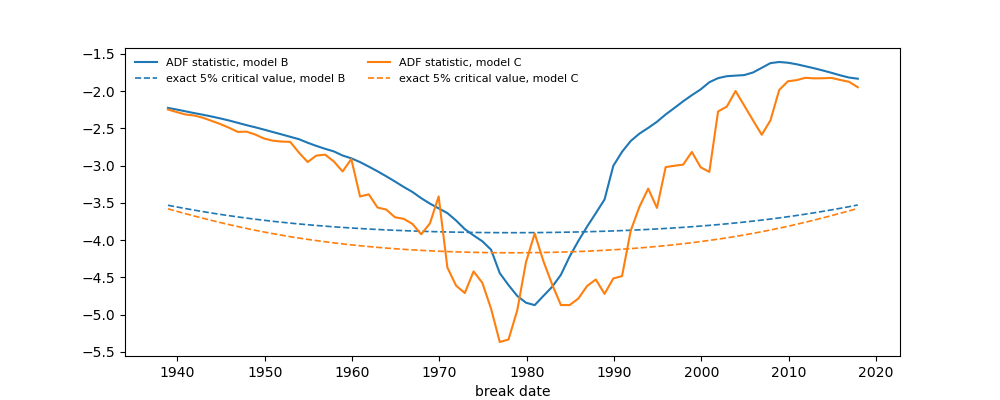

In [9]:
grid = [i for i, d in enumerate(dates) if d.month == 12 and TRIM * n <= i + 1 <= (1 - TRIM) * n]
stats = {m: [adf(y, i + 1, m)[0] for i in grid] for m in ("B", "C")}
crits = {m: [critical_values(m, round((i + 1) / n, 4))[1] for i in grid] for m in ("B", "C")}

fig, ax = plt.subplots(figsize=(10, 4))
for m, col in (("B", "C0"), ("C", "C1")):
    ax.plot(grid, stats[m], color=col, lw=1.5, label=f"ADF statistic, model {m}")
    ax.plot(grid, crits[m], color=col, lw=1.2, ls="--", label=f"exact 5% critical value, model {m}")
ax.set_xticks(years, [dates[j].year for j in years]); ax.set_xlim(0, n - 1)
ax.set_xlabel("break date"); ax.legend(fontsize=8, frameon=False, ncol=2)
plt.show()

### References

* Bao, Y., Broda, S. A. and Kan, R. (2026). The exact limiting distribution of the Dickey-Fuller $t$-ratio with general deterministic terms. Working paper, [SSRN 7745921](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=7745921).
* Perron, P. (1989). The great crash, the oil price shock, and the unit root hypothesis. *Econometrica* 57, 1361-1401.
* Zivot, E. and Andrews, D. W. K. (1992). Further evidence on the great crash, the oil-price shock, and the unit-root hypothesis. *Journal of Business & Economic Statistics* 10, 251-270.